In [24]:
!pip install pandas numpy matplotlib seaborn requests scikit-learn


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip


In [25]:
# Import the required libraries
import pandas
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import requests

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

# DF1 Preparation

In [26]:
df1 = pandas.read_csv('https://raw.githubusercontent.com/Uwanga14/netflix_customer_churn/main/dataset1_subscriber.csv')

In [27]:
df1.head(10)

,subscriber_id,subscription_type,subscription_status,converted_to_paid,churn_status,sign_up_date,churn_date,acquisition_channel
0,Sub1432,streaming,cancelled,NaN,yes,2025-01-07,2025-07-06,Instagram ad
1,Sub1434,satellite,active,NaN,no,2026-06-03,NaN,Google search
2,Sub1435,satellite,cancelled,no,yes,2026-03-13,2026-03-29,Retail partner
3,Sub1437,hybrid,cancelled,NaN,yes,2025-01-23,2025-03-24,Referral
4,Sub1438,streaming,cancelled,no,yes,2024-11-29,2024-12-28,Organic
5,Sub1441,streaming,cancelled,NaN,yes,2024-08-24,2025-10-18,TV promo
6,Sub1444,streaming,active,NaN,no,2026-07-27,NaN,TV promo
7,Sub1447,streaming,cancelled,NaN,yes,2024-07-08,2025-01-04,Call centre
8,Sub1450,satellite,active,NaN,no,2026-07-03,NaN,Retail partner
9,Sub1453,satellite,active,NaN,no,2024-12-23,NaN,Retail partner


In [28]:
missing_values = df1.isnull().sum()
missing_values

subscriber_id             0
subscription_type         0
subscription_status       0
converted_to_paid      2562
churn_status              0
sign_up_date              0
churn_date             1787
acquisition_channel       0
dtype: int64

In [29]:
# Calculate missing value percentages
missing_percentage = (
    df1.isnull().sum() / len(df1) * 100
).round(2)

print("\nMissing values (%):")
print(missing_percentage[missing_percentage > 0])


Missing values (%):
converted_to_paid    60.83
churn_date           42.43
dtype: float64


In [30]:
# Examine churn status against subscription status
print(
    pandas.crosstab(
        df1['subscription_status'],
        df1['churn_status'],
        dropna=False
    )
)

churn_status           no   yes
subscription_status            
 active                 7     0
 cancelled              0     9
ACTIVE                  7     0
CANCELLED               0    10
active               1647     0
active                  8     0
cancelled               0  2388
cancelled               0    18
suspended             118     0


In [31]:
# Standardise subscription status
df1['subscription_status'] = (
    df1['subscription_status']
    .str.strip()
    .str.lower()
)

In [32]:
# Check the cleaned categories against churn status
print(
    pandas.crosstab(
        df1['subscription_status'],
        df1['churn_status'],
        dropna=False
    )
)

churn_status           no   yes
subscription_status            
active               1669     0
cancelled               0  2425
suspended             118     0


### Analysis of Subscription Status and Churn Status

A cross-tabulation was performed using `pandas.crosstab()` to examine the relationship between `subscription_status` and `churn_status`. The purpose of this analysis was to understand how the current subscription status relates to whether a subscriber has churned.

The results showed that active subscribers were recorded as not having churned, while cancelled subscribers were recorded as having churned. The dataset also contained 118 suspended subscribers who were classified as not having churned. These findings suggest a strong relationship between subscription status and churn status. However, the analysis also revealed inconsistent formatting, including uppercase and lowercase versions of the same categories, such as `ACTIVE`, `active`, `CANCELLED` and `cancelled`. These inconsistencies need to be corrected during data cleaning to ensure accurate analysis.

An important consideration is that `subscription_status` may cause target leakage when used to predict `churn_status`. Since cancelled subscriptions appear to correspond directly with churn, a machine learning model could use this variable to identify subscribers who have already churned rather than predict which subscribers are likely to churn in the future. Therefore, the availability and timing of this variable should be investigated before it is included in the model. If subscription status reflects a cancellation that has already occurred, it should be excluded from the predictor variables.

Overall, this analysis provides an initial understanding of the relationship between subscription status and churn. Standardising the category labels and preventing target leakage will help improve the reliability of the subsequent churn prediction model.

In [33]:
# Check missing churn dates by churn status
print(
    df1.groupby('churn_status', dropna=False)['churn_date']
       .apply(lambda x: x.isnull().sum())
)

churn_status
no     1787
yes       0
Name: churn_date, dtype: int64


The analysis found that 1,787 subscribers classified as not churned had missing churn dates, while all subscribers classified as churned had recorded churn dates. This pattern is consistent with the meaning of the data, as subscribers who have not churned would not normally have a cancellation date. Therefore, the missing values in churn_date is retained rather than imputed. Since the objective is to predict future churn, churn_date should also be excluded from the model predictors because it can reveal whether churn has already occurred.

In [34]:
# Fill missing values
df1['converted_to_paid'] = (
    df1['converted_to_paid']
    .fillna('unknown')
    .str.lower()
)

# Check distribution
print(df1['converted_to_paid'].value_counts())


converted_to_paid
unknown    2562
no         1082
yes         568
Name: count, dtype: int64


In [35]:
df1 = pandas.get_dummies(
    df1,
    columns=['converted_to_paid'],
    dtype=int
)

In [36]:
print(df1.filter(like='converted_to_paid').head())

   converted_to_paid_no  converted_to_paid_unknown  converted_to_paid_yes
0                     0                          1                      0
1                     0                          1                      0
2                     1                          0                      0
3                     0                          1                      0
4                     1                          0                      0


The converted_to_paid variable was retained because it may influence subscriber churn behaviour. Missing values were replaced with "unknown" and the variable was one-hot encoded to preserve all available information and avoid losing potentially useful customer conversion patterns.

In [37]:
df1.head(10)

,subscriber_id,subscription_type,subscription_status,churn_status,sign_up_date,churn_date,acquisition_channel,converted_to_paid_no,converted_to_paid_unknown,converted_to_paid_yes
0,Sub1432,streaming,cancelled,yes,2025-01-07,2025-07-06,Instagram ad,0,1,0
1,Sub1434,satellite,active,no,2026-06-03,NaN,Google search,0,1,0
2,Sub1435,satellite,cancelled,yes,2026-03-13,2026-03-29,Retail partner,1,0,0
3,Sub1437,hybrid,cancelled,yes,2025-01-23,2025-03-24,Referral,0,1,0
4,Sub1438,streaming,cancelled,yes,2024-11-29,2024-12-28,Organic,1,0,0
5,Sub1441,streaming,cancelled,yes,2024-08-24,2025-10-18,TV promo,0,1,0
6,Sub1444,streaming,active,no,2026-07-27,NaN,TV promo,0,1,0
7,Sub1447,streaming,cancelled,yes,2024-07-08,2025-01-04,Call centre,0,1,0
8,Sub1450,satellite,active,no,2026-07-03,NaN,Retail partner,0,1,0
9,Sub1453,satellite,active,no,2024-12-23,NaN,Retail partner,0,1,0


##Check the Target Variable Distribution

In [38]:
print(df1['churn_status'].value_counts())

print(
    (df1['churn_status'].value_counts(normalize=True) * 100)
    .round(2)
)

churn_status
yes    2425
no     1787
Name: count, dtype: int64
churn_status
yes    57.57
no     42.43
Name: proportion, dtype: float64


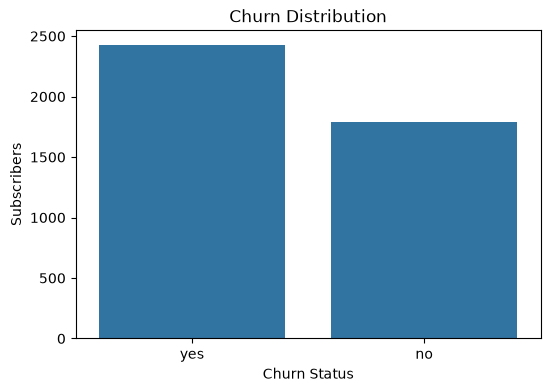

In [39]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(6,4))

sns.countplot(
    data=df1,
    x='churn_status'
)

plt.title('Churn Distribution')
plt.xlabel('Churn Status')
plt.ylabel('Subscribers')

plt.show()

In [40]:
df1.info()

<class 'pandas.DataFrame'>
RangeIndex: 4212 entries, 0 to 4211
Data columns (total 10 columns):
 #   Column                     Non-Null Count  Dtype
---  ------                     --------------  -----
 0   subscriber_id              4212 non-null   str  
 1   subscription_type          4212 non-null   str  
 2   subscription_status        4212 non-null   str  
 3   churn_status               4212 non-null   str  
 4   sign_up_date               4212 non-null   str  
 5   churn_date                 2425 non-null   str  
 6   acquisition_channel        4212 non-null   str  
 7   converted_to_paid_no       4212 non-null   int64
 8   converted_to_paid_unknown  4212 non-null   int64
 9   converted_to_paid_yes      4212 non-null   int64
dtypes: int64(3), str(7)
memory usage: 329.2 KB


In [41]:
# Count subscribers by acquisition_channel
print(df1['acquisition_channel'].value_counts())

acquisition_channel
Facebook ad         787
Organic             685
Google search       675
Retail partner      562
Referral            508
Instagram ad        453
Call centre         252
TV promo            188
REFERRAL              6
Organic               6
retail partner        6
google search         6
 Google search        6
 Organic              6
 Retail partner       5
Facebook ad           5
RETAIL PARTNER        4
Referral              4
organic               4
Google search         4
call centre           3
TV PROMO              3
FACEBOOK AD           3
ORGANIC               3
facebook ad           3
 TV promo             3
INSTAGRAM AD          2
referral              2
Retail partner        2
tv promo              2
 Referral             2
TV promo              2
CALL CENTRE           2
instagram ad          2
 Instagram ad         1
Instagram ad          1
 Call centre          1
 Facebook ad          1
GOOGLE SEARCH         1
Call centre           1
Name: count, dtype: 

In [42]:
# Standardise acquisition_channel
df1['acquisition_channel'] = (
    df1['acquisition_channel']
    .str.strip()
    .str.lower()
)

# Check the corrected categories
print(df1['acquisition_channel'].value_counts(dropna=False))

acquisition_channel
facebook ad       799
organic           704
google search     692
retail partner    579
referral          522
instagram ad      459
call centre       259
tv promo          198
Name: count, dtype: int64


In [43]:
# One-hot encode churn_status
df1 = pandas.get_dummies(
    df1,
    columns=['acquisition_channel'],
    dtype=int
)

In [44]:
df1.head(10)

,subscriber_id,subscription_type,subscription_status,churn_status,sign_up_date,churn_date,converted_to_paid_no,converted_to_paid_unknown,converted_to_paid_yes,acquisition_channel_call centre,acquisition_channel_facebook ad,acquisition_channel_google search,acquisition_channel_instagram ad,acquisition_channel_organic,acquisition_channel_referral,acquisition_channel_retail partner,acquisition_channel_tv promo
0,Sub1432,streaming,cancelled,yes,2025-01-07,2025-07-06,0,1,0,0,0,0,1,0,0,0,0
1,Sub1434,satellite,active,no,2026-06-03,NaN,0,1,0,0,0,1,0,0,0,0,0
2,Sub1435,satellite,cancelled,yes,2026-03-13,2026-03-29,1,0,0,0,0,0,0,0,0,1,0
3,Sub1437,hybrid,cancelled,yes,2025-01-23,2025-03-24,0,1,0,0,0,0,0,0,1,0,0
4,Sub1438,streaming,cancelled,yes,2024-11-29,2024-12-28,1,0,0,0,0,0,0,1,0,0,0
5,Sub1441,streaming,cancelled,yes,2024-08-24,2025-10-18,0,1,0,0,0,0,0,0,0,0,1
6,Sub1444,streaming,active,no,2026-07-27,NaN,0,1,0,0,0,0,0,0,0,0,1
7,Sub1447,streaming,cancelled,yes,2024-07-08,2025-01-04,0,1,0,1,0,0,0,0,0,0,0
8,Sub1450,satellite,active,no,2026-07-03,NaN,0,1,0,0,0,0,0,0,0,1,0
9,Sub1453,satellite,active,no,2024-12-23,NaN,0,1,0,0,0,0,0,0,0,1,0


In [45]:
# Count subscribers by churn_status
print(df1['churn_status'].value_counts())

churn_status
yes    2425
no     1787
Name: count, dtype: int64


In [46]:
# One-hot encode churn_status
df1 = pandas.get_dummies(
    df1,
    columns=['churn_status'],
    dtype=int
)

In [47]:
df1.head(10)

,subscriber_id,subscription_type,subscription_status,sign_up_date,churn_date,converted_to_paid_no,converted_to_paid_unknown,converted_to_paid_yes,acquisition_channel_call centre,acquisition_channel_facebook ad,acquisition_channel_google search,acquisition_channel_instagram ad,acquisition_channel_organic,acquisition_channel_referral,acquisition_channel_retail partner,acquisition_channel_tv promo,churn_status_no,churn_status_yes
0,Sub1432,streaming,cancelled,2025-01-07,2025-07-06,0,1,0,0,0,0,1,0,0,0,0,0,1
1,Sub1434,satellite,active,2026-06-03,NaN,0,1,0,0,0,1,0,0,0,0,0,1,0
2,Sub1435,satellite,cancelled,2026-03-13,2026-03-29,1,0,0,0,0,0,0,0,0,1,0,0,1
3,Sub1437,hybrid,cancelled,2025-01-23,2025-03-24,0,1,0,0,0,0,0,0,1,0,0,0,1
4,Sub1438,streaming,cancelled,2024-11-29,2024-12-28,1,0,0,0,0,0,0,1,0,0,0,0,1
5,Sub1441,streaming,cancelled,2024-08-24,2025-10-18,0,1,0,0,0,0,0,0,0,0,1,0,1
6,Sub1444,streaming,active,2026-07-27,NaN,0,1,0,0,0,0,0,0,0,0,1,1,0
7,Sub1447,streaming,cancelled,2024-07-08,2025-01-04,0,1,0,1,0,0,0,0,0,0,0,0,1
8,Sub1450,satellite,active,2026-07-03,NaN,0,1,0,0,0,0,0,0,0,1,0,1,0
9,Sub1453,satellite,active,2024-12-23,NaN,0,1,0,0,0,0,0,0,0,1,0,1,0


In [48]:
# Count subscribers by subscription status
print(df1['subscription_status'].value_counts())

subscription_status
cancelled    2425
active       1669
suspended     118
Name: count, dtype: int64


In [49]:
# One-hot encode subscription_status
df1 = pandas.get_dummies(
    df1,
    columns=['subscription_status'],
    dtype=int
)

In [50]:
df1.head(10)

,subscriber_id,subscription_type,sign_up_date,churn_date,converted_to_paid_no,converted_to_paid_unknown,converted_to_paid_yes,acquisition_channel_call centre,acquisition_channel_facebook ad,acquisition_channel_google search,acquisition_channel_instagram ad,acquisition_channel_organic,acquisition_channel_referral,acquisition_channel_retail partner,acquisition_channel_tv promo,churn_status_no,churn_status_yes,subscription_status_active,subscription_status_cancelled,subscription_status_suspended
0,Sub1432,streaming,2025-01-07,2025-07-06,0,1,0,0,0,0,1,0,0,0,0,0,1,0,1,0
1,Sub1434,satellite,2026-06-03,NaN,0,1,0,0,0,1,0,0,0,0,0,1,0,1,0,0
2,Sub1435,satellite,2026-03-13,2026-03-29,1,0,0,0,0,0,0,0,0,1,0,0,1,0,1,0
3,Sub1437,hybrid,2025-01-23,2025-03-24,0,1,0,0,0,0,0,0,1,0,0,0,1,0,1,0
4,Sub1438,streaming,2024-11-29,2024-12-28,1,0,0,0,0,0,0,1,0,0,0,0,1,0,1,0
5,Sub1441,streaming,2024-08-24,2025-10-18,0,1,0,0,0,0,0,0,0,0,1,0,1,0,1,0
6,Sub1444,streaming,2026-07-27,NaN,0,1,0,0,0,0,0,0,0,0,1,1,0,1,0,0
7,Sub1447,streaming,2024-07-08,2025-01-04,0,1,0,1,0,0,0,0,0,0,0,0,1,0,1,0
8,Sub1450,satellite,2026-07-03,NaN,0,1,0,0,0,0,0,0,0,1,0,1,0,1,0,0
9,Sub1453,satellite,2024-12-23,NaN,0,1,0,0,0,0,0,0,0,1,0,1,0,1,0,0


In [51]:
# Count subscribers by subscription type
print(df1['subscription_type'].value_counts())

subscription_type
streaming      2586
satellite      1070
hybrid          492
 streaming       16
STREAMING        12
streaming        11
satellite         8
SATELLITE         7
hybrid            5
 satellite        3
 hybrid           2
Name: count, dtype: int64


In [52]:
# Standardise subscription_type
df1['subscription_type'] = (
    df1['subscription_type']
    .str.strip()
    .str.lower()
)

# Check the corrected categories
print(df1['subscription_type'].value_counts(dropna=False))

subscription_type
streaming    2625
satellite    1088
hybrid        499
Name: count, dtype: int64


In [53]:
# One-hot encode subscription_type
df1 = pandas.get_dummies(
    df1,
    columns=['subscription_type'],
    dtype=int
)

In [54]:
df1.head(10)

,subscriber_id,sign_up_date,churn_date,converted_to_paid_no,converted_to_paid_unknown,converted_to_paid_yes,acquisition_channel_call centre,acquisition_channel_facebook ad,acquisition_channel_google search,acquisition_channel_instagram ad,...,acquisition_channel_retail partner,acquisition_channel_tv promo,churn_status_no,churn_status_yes,subscription_status_active,subscription_status_cancelled,subscription_status_suspended,subscription_type_hybrid,subscription_type_satellite,subscription_type_streaming
0,Sub1432,2025-01-07,2025-07-06,0,1,0,0,0,0,1,...,0,0,0,1,0,1,0,0,0,1
1,Sub1434,2026-06-03,NaN,0,1,0,0,0,1,0,...,0,0,1,0,1,0,0,0,1,0
2,Sub1435,2026-03-13,2026-03-29,1,0,0,0,0,0,0,...,1,0,0,1,0,1,0,0,1,0
3,Sub1437,2025-01-23,2025-03-24,0,1,0,0,0,0,0,...,0,0,0,1,0,1,0,1,0,0
4,Sub1438,2024-11-29,2024-12-28,1,0,0,0,0,0,0,...,0,0,0,1,0,1,0,0,0,1
5,Sub1441,2024-08-24,2025-10-18,0,1,0,0,0,0,0,...,0,1,0,1,0,1,0,0,0,1
6,Sub1444,2026-07-27,NaN,0,1,0,0,0,0,0,...,0,1,1,0,1,0,0,0,0,1
7,Sub1447,2024-07-08,2025-01-04,0,1,0,1,0,0,0,...,0,0,0,1,0,1,0,0,0,1
8,Sub1450,2026-07-03,NaN,0,1,0,0,0,0,0,...,1,0,1,0,1,0,0,0,1,0
9,Sub1453,2024-12-23,NaN,0,1,0,0,0,0,0,...,1,0,1,0,1,0,0,0,1,0


In [55]:
df1.info()

<class 'pandas.DataFrame'>
RangeIndex: 4212 entries, 0 to 4211
Data columns (total 22 columns):
 #   Column                              Non-Null Count  Dtype
---  ------                              --------------  -----
 0   subscriber_id                       4212 non-null   str  
 1   sign_up_date                        4212 non-null   str  
 2   churn_date                          2425 non-null   str  
 3   converted_to_paid_no                4212 non-null   int64
 4   converted_to_paid_unknown           4212 non-null   int64
 5   converted_to_paid_yes               4212 non-null   int64
 6   acquisition_channel_call centre     4212 non-null   int64
 7   acquisition_channel_facebook ad     4212 non-null   int64
 8   acquisition_channel_google search   4212 non-null   int64
 9   acquisition_channel_instagram ad    4212 non-null   int64
 10  acquisition_channel_organic         4212 non-null   int64
 11  acquisition_channel_referral        4212 non-null   int64
 12  acquisition_chann

In [56]:
df1.head(10)

,subscriber_id,sign_up_date,churn_date,converted_to_paid_no,converted_to_paid_unknown,converted_to_paid_yes,acquisition_channel_call centre,acquisition_channel_facebook ad,acquisition_channel_google search,acquisition_channel_instagram ad,...,acquisition_channel_retail partner,acquisition_channel_tv promo,churn_status_no,churn_status_yes,subscription_status_active,subscription_status_cancelled,subscription_status_suspended,subscription_type_hybrid,subscription_type_satellite,subscription_type_streaming
0,Sub1432,2025-01-07,2025-07-06,0,1,0,0,0,0,1,...,0,0,0,1,0,1,0,0,0,1
1,Sub1434,2026-06-03,NaN,0,1,0,0,0,1,0,...,0,0,1,0,1,0,0,0,1,0
2,Sub1435,2026-03-13,2026-03-29,1,0,0,0,0,0,0,...,1,0,0,1,0,1,0,0,1,0
3,Sub1437,2025-01-23,2025-03-24,0,1,0,0,0,0,0,...,0,0,0,1,0,1,0,1,0,0
4,Sub1438,2024-11-29,2024-12-28,1,0,0,0,0,0,0,...,0,0,0,1,0,1,0,0,0,1
5,Sub1441,2024-08-24,2025-10-18,0,1,0,0,0,0,0,...,0,1,0,1,0,1,0,0,0,1
6,Sub1444,2026-07-27,NaN,0,1,0,0,0,0,0,...,0,1,1,0,1,0,0,0,0,1
7,Sub1447,2024-07-08,2025-01-04,0,1,0,1,0,0,0,...,0,0,0,1,0,1,0,0,0,1
8,Sub1450,2026-07-03,NaN,0,1,0,0,0,0,0,...,1,0,1,0,1,0,0,0,1,0
9,Sub1453,2024-12-23,NaN,0,1,0,0,0,0,0,...,1,0,1,0,1,0,0,0,1,0


In [57]:
df1.head(10)

,subscriber_id,sign_up_date,churn_date,converted_to_paid_no,converted_to_paid_unknown,converted_to_paid_yes,acquisition_channel_call centre,acquisition_channel_facebook ad,acquisition_channel_google search,acquisition_channel_instagram ad,...,acquisition_channel_retail partner,acquisition_channel_tv promo,churn_status_no,churn_status_yes,subscription_status_active,subscription_status_cancelled,subscription_status_suspended,subscription_type_hybrid,subscription_type_satellite,subscription_type_streaming
0,Sub1432,2025-01-07,2025-07-06,0,1,0,0,0,0,1,...,0,0,0,1,0,1,0,0,0,1
1,Sub1434,2026-06-03,NaN,0,1,0,0,0,1,0,...,0,0,1,0,1,0,0,0,1,0
2,Sub1435,2026-03-13,2026-03-29,1,0,0,0,0,0,0,...,1,0,0,1,0,1,0,0,1,0
3,Sub1437,2025-01-23,2025-03-24,0,1,0,0,0,0,0,...,0,0,0,1,0,1,0,1,0,0
4,Sub1438,2024-11-29,2024-12-28,1,0,0,0,0,0,0,...,0,0,0,1,0,1,0,0,0,1
5,Sub1441,2024-08-24,2025-10-18,0,1,0,0,0,0,0,...,0,1,0,1,0,1,0,0,0,1
6,Sub1444,2026-07-27,NaN,0,1,0,0,0,0,0,...,0,1,1,0,1,0,0,0,0,1
7,Sub1447,2024-07-08,2025-01-04,0,1,0,1,0,0,0,...,0,0,0,1,0,1,0,0,0,1
8,Sub1450,2026-07-03,NaN,0,1,0,0,0,0,0,...,1,0,1,0,1,0,0,0,1,0
9,Sub1453,2024-12-23,NaN,0,1,0,0,0,0,0,...,1,0,1,0,1,0,0,0,1,0


In [58]:
# Create a copy of the dataset
df1_model = df1.copy()

In [59]:
# Reconstruct the target variable
# 1 = churned, 0 = not churned
df1_model['churn_status'] = df1_model['churn_status_yes']

In [60]:
df1_model.head(10)

,subscriber_id,sign_up_date,churn_date,converted_to_paid_no,converted_to_paid_unknown,converted_to_paid_yes,acquisition_channel_call centre,acquisition_channel_facebook ad,acquisition_channel_google search,acquisition_channel_instagram ad,...,acquisition_channel_tv promo,churn_status_no,churn_status_yes,subscription_status_active,subscription_status_cancelled,subscription_status_suspended,subscription_type_hybrid,subscription_type_satellite,subscription_type_streaming,churn_status
0,Sub1432,2025-01-07,2025-07-06,0,1,0,0,0,0,1,...,0,0,1,0,1,0,0,0,1,1
1,Sub1434,2026-06-03,NaN,0,1,0,0,0,1,0,...,0,1,0,1,0,0,0,1,0,0
2,Sub1435,2026-03-13,2026-03-29,1,0,0,0,0,0,0,...,0,0,1,0,1,0,0,1,0,1
3,Sub1437,2025-01-23,2025-03-24,0,1,0,0,0,0,0,...,0,0,1,0,1,0,1,0,0,1
4,Sub1438,2024-11-29,2024-12-28,1,0,0,0,0,0,0,...,0,0,1,0,1,0,0,0,1,1
5,Sub1441,2024-08-24,2025-10-18,0,1,0,0,0,0,0,...,1,0,1,0,1,0,0,0,1,1
6,Sub1444,2026-07-27,NaN,0,1,0,0,0,0,0,...,1,1,0,1,0,0,0,0,1,0
7,Sub1447,2024-07-08,2025-01-04,0,1,0,1,0,0,0,...,0,0,1,0,1,0,0,0,1,1
8,Sub1450,2026-07-03,NaN,0,1,0,0,0,0,0,...,0,1,0,1,0,0,0,1,0,0
9,Sub1453,2024-12-23,NaN,0,1,0,0,0,0,0,...,0,1,0,1,0,0,0,1,0,0


In [61]:
# Drop identifiers, dates, text columns and leakage-prone columns
columns_to_drop = [
    'converted_to_paid',
    'sign_up_date',
    'churn_date',
    'churn_status_no',
    'churn_status_yes',
    'subscription_status_active',
    'subscription_status_cancelled',
    'subscription_status_suspended'
]

df1_model = df1_model.drop(
    columns=columns_to_drop,
    errors='ignore'
)

The following columns were removed from the analysis because they either do not provide useful predictive information, risk introducing target leakage, or require additional preprocessing before they can be meaningfully used. subscriber_id was excluded because it is simply a unique identifier and does not reflect customer behaviour. converted_to_paid was dropped due to its large number of missing values and because it is currently stored as a string variable that requires further assessment. sign_up_date was removed because, in its raw date format, it is not directly useful for modelling; however, it could later be transformed into a tenure-related feature if a suitable prediction date is available. churn_date was excluded to prevent target leakage, as it directly reveals when a customer churned. The dummy variables churn_status_no and churn_status_yes were removed because they were consolidated into a single target variable, churn_status. Finally, subscription_status_active, subscription_status_cancelled, and subscription_status_suspended were initially excluded because they may directly indicate or closely correlate with the churn outcome, potentially biasing the model's predictions.

In [62]:
df1_model.info()

<class 'pandas.DataFrame'>
RangeIndex: 4212 entries, 0 to 4211
Data columns (total 16 columns):
 #   Column                              Non-Null Count  Dtype
---  ------                              --------------  -----
 0   subscriber_id                       4212 non-null   str  
 1   converted_to_paid_no                4212 non-null   int64
 2   converted_to_paid_unknown           4212 non-null   int64
 3   converted_to_paid_yes               4212 non-null   int64
 4   acquisition_channel_call centre     4212 non-null   int64
 5   acquisition_channel_facebook ad     4212 non-null   int64
 6   acquisition_channel_google search   4212 non-null   int64
 7   acquisition_channel_instagram ad    4212 non-null   int64
 8   acquisition_channel_organic         4212 non-null   int64
 9   acquisition_channel_referral        4212 non-null   int64
 10  acquisition_channel_retail partner  4212 non-null   int64
 11  acquisition_channel_tv promo        4212 non-null   int64
 12  subscription_type

In [63]:
df1_model.head(10)

,subscriber_id,converted_to_paid_no,converted_to_paid_unknown,converted_to_paid_yes,acquisition_channel_call centre,acquisition_channel_facebook ad,acquisition_channel_google search,acquisition_channel_instagram ad,acquisition_channel_organic,acquisition_channel_referral,acquisition_channel_retail partner,acquisition_channel_tv promo,subscription_type_hybrid,subscription_type_satellite,subscription_type_streaming,churn_status
0,Sub1432,0,1,0,0,0,0,1,0,0,0,0,0,0,1,1
1,Sub1434,0,1,0,0,0,1,0,0,0,0,0,0,1,0,0
2,Sub1435,1,0,0,0,0,0,0,0,0,1,0,0,1,0,1
3,Sub1437,0,1,0,0,0,0,0,0,1,0,0,1,0,0,1
4,Sub1438,1,0,0,0,0,0,0,1,0,0,0,0,0,1,1
5,Sub1441,0,1,0,0,0,0,0,0,0,0,1,0,0,1,1
6,Sub1444,0,1,0,0,0,0,0,0,0,0,1,0,0,1,0
7,Sub1447,0,1,0,1,0,0,0,0,0,0,0,0,0,1,1
8,Sub1450,0,1,0,0,0,0,0,0,0,1,0,0,1,0,0
9,Sub1453,0,1,0,0,0,0,0,0,0,1,0,0,1,0,0


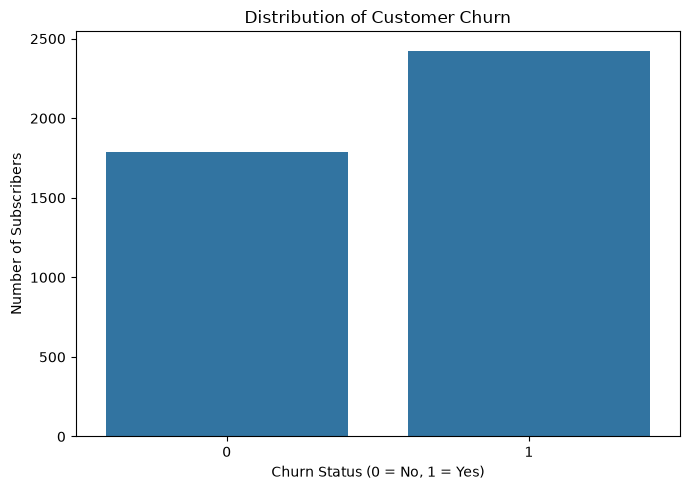

In [64]:

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df1_model,
    x='churn_status'
)

plt.title('Distribution of Customer Churn')
plt.xlabel('Churn Status (0 = No, 1 = Yes)')
plt.ylabel('Number of Subscribers')
plt.tight_layout()
plt.show()


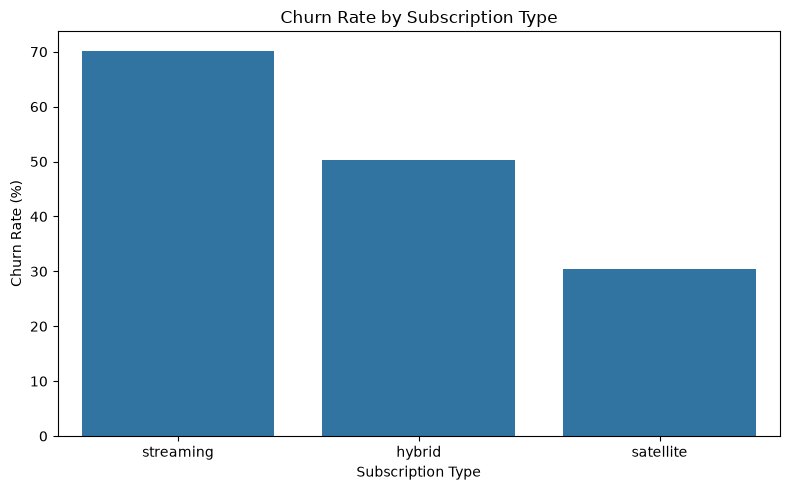

In [65]:
#Visualisation: Churn by subscription type
subscription_cols = [
    'subscription_type_hybrid',
    'subscription_type_satellite',
    'subscription_type_streaming'
]

# Calculate churn rate for each subscription type
subscription_churn = {}

for col in subscription_cols:
    if col in df1.columns:
        mask = df1[col] == 1
        subscription_churn[col.replace(
            'subscription_type_', ''
        )] = df1_model.loc[
            mask, 'churn_status'
        ].mean() * 100

subscription_churn = pandas.Series(
    subscription_churn
).sort_values(ascending=False)

plt.figure(figsize=(8, 5))

sns.barplot(
    x=subscription_churn.index,
    y=subscription_churn.values
)

plt.title('Churn Rate by Subscription Type')
plt.xlabel('Subscription Type')
plt.ylabel('Churn Rate (%)')
plt.tight_layout()
plt.show()


It identifies subscription types with higher observed churn rates. The business can investigate whether pricing, content preferences or service experiences differ across these groups before designing targeted retention strategies.

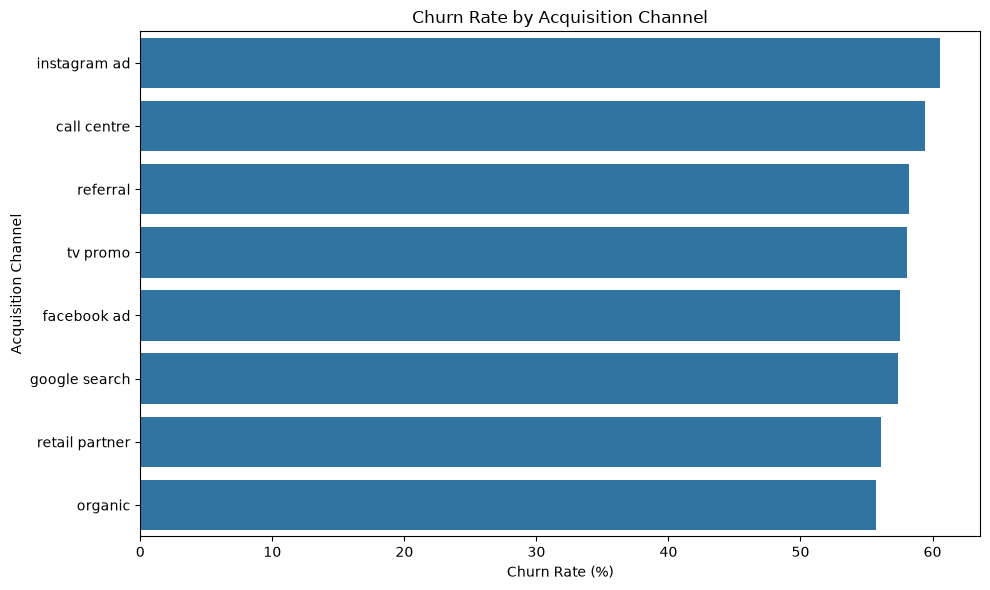

In [66]:
#Visualisation: Churn by acquisition channel

channel_cols = [
    col for col in df1_model.columns
    if col.startswith('acquisition_channel_')
]

channel_churn = {}

for col in channel_cols:
    mask = df1_model[col] == 1
    channel_churn[col.replace(
        'acquisition_channel_', ''
    )] = df1_model.loc[
        mask, 'churn_status'
    ].mean() * 100

channel_churn = pandas.Series(
    channel_churn
).sort_values(ascending=False)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=channel_churn.values,
    y=channel_churn.index
)

plt.title('Churn Rate by Acquisition Channel')
plt.xlabel('Churn Rate (%)')
plt.ylabel('Acquisition Channel')
plt.tight_layout()
plt.show()


It helps identify acquisition channels associated with higher churn. The business could investigate whether some channels attract subscribers who are less likely to remain subscribed and adjust marketing campaigns accordingly.

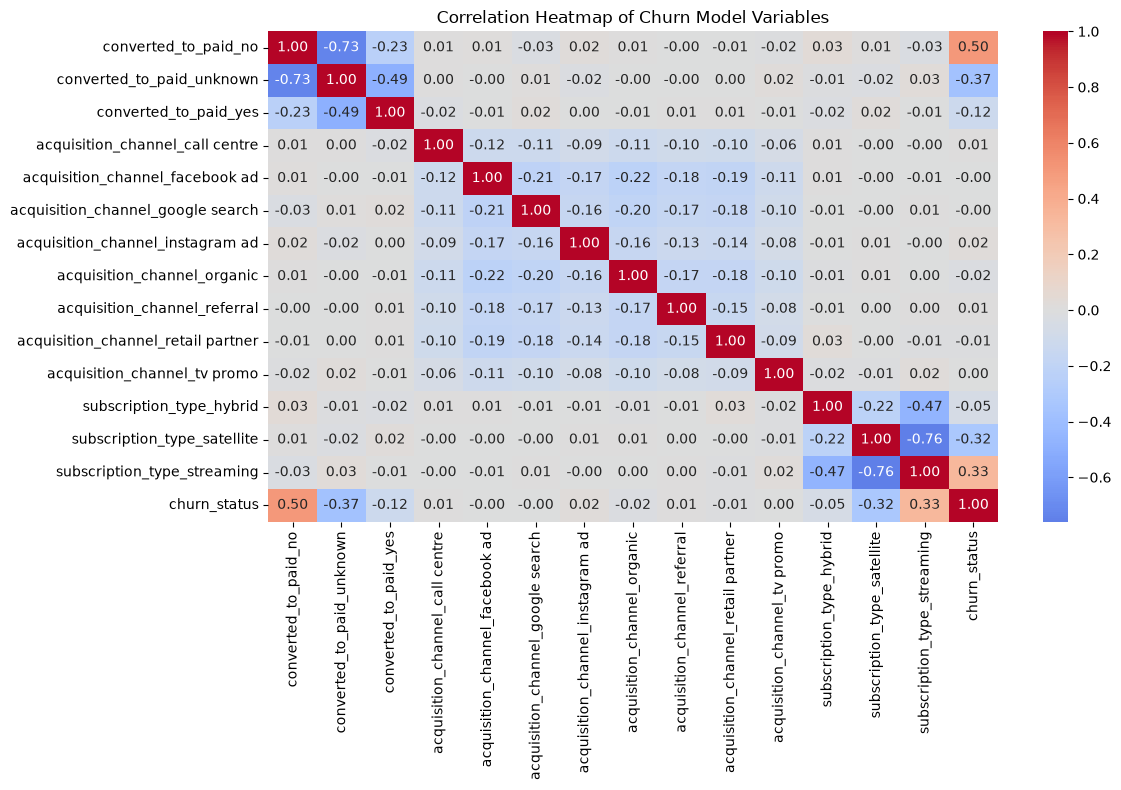

In [67]:
#Correlation heatmap

plt.figure(figsize=(12, 8))

correlation_matrix = df1_model.corr(numeric_only=True)

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    center=0
)

plt.title('Correlation Heatmap of Churn Model Variables')
plt.tight_layout()
plt.show()


It highlights which encoded variables have stronger positive or negative associations with churn.

# DF2 preperation

In [68]:
df2 = pandas.read_csv('https://raw.githubusercontent.com/Uwanga14/netflix_customer_churn/main/dataset2_subscription_billing_history.csv')

In [69]:
df2.head(10)

,subscriber_id,billing_date,plan_name,monthly_fee,payment_status,payment_failure_count,downgrade_flag,auto_renewal,retention_outcome,cancellation_request_date,tenure
0,Sub1432,2025-01-07,Stream Premium,355,successful,0,no,yes,churned,2025-07-04,1
1,Sub1432,2025-02-06,Stream Premium,355,successful,0,no,no,churned,2025-07-04,30
2,Sub1432,2025-03-08,Stream Premium,355,successful,0,no,yes,churned,2025-07-04,60
3,Sub1432,2025-04-07,Stream Premium,355,failed,1,no,yes,churned,2025-07-04,90
4,Sub1432,2025-05-07,Stream Premium,355,reversed,2,no,yes,churned,2025-07-04,120
5,Sub1432,2025-06-06,Stream Premium,355,successful,2,no,yes,churned,2025-07-04,150
6,Sub1434,2026-06-03,Compact Plus,549,successful,0,no,no,retained,NaN,1
7,Sub1434,2026-07-03,Compact Plus,549,successful,0,no,yes,retained,NaN,30
8,Sub1434,2026-08-02,Compact Plus,549,successful,0,no,yes,retained,NaN,60
9,Sub1435,2026-03-13,Compact,289,successful,0,no,yes,churned,2026-03-29,1


In [70]:
df2.info()

<class 'pandas.DataFrame'>
RangeIndex: 26535 entries, 0 to 26534
Data columns (total 11 columns):
 #   Column                     Non-Null Count  Dtype
---  ------                     --------------  -----
 0   subscriber_id              26535 non-null  str  
 1   billing_date               26535 non-null  str  
 2   plan_name                  26535 non-null  str  
 3   monthly_fee                26535 non-null  int64
 4   payment_status             26535 non-null  str  
 5   payment_failure_count      26535 non-null  int64
 6   downgrade_flag             26535 non-null  str  
 7   auto_renewal               26535 non-null  str  
 8   retention_outcome          26535 non-null  str  
 9   cancellation_request_date  8335 non-null   str  
 10  tenure                     26535 non-null  int64
dtypes: int64(3), str(8)
memory usage: 2.2 MB


In [71]:
# Create a copy for cleaning
df2_clean = df2.copy()

In [72]:
df2_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 26535 entries, 0 to 26534
Data columns (total 11 columns):
 #   Column                     Non-Null Count  Dtype
---  ------                     --------------  -----
 0   subscriber_id              26535 non-null  str  
 1   billing_date               26535 non-null  str  
 2   plan_name                  26535 non-null  str  
 3   monthly_fee                26535 non-null  int64
 4   payment_status             26535 non-null  str  
 5   payment_failure_count      26535 non-null  int64
 6   downgrade_flag             26535 non-null  str  
 7   auto_renewal               26535 non-null  str  
 8   retention_outcome          26535 non-null  str  
 9   cancellation_request_date  8335 non-null   str  
 10  tenure                     26535 non-null  int64
dtypes: int64(3), str(8)
memory usage: 2.2 MB


In [73]:
# Count subscribers by plan_name
print(df2_clean['plan_name'].value_counts())

plan_name
Stream Standard       4389
Stream Lite           4210
Stream Premium        4135
Access                2510
Compact Plus          2477
Premium               2474
Compact               2250
Compact + Stream      1856
Premium Plus          1677
Stream Standard         31
STREAM LITE             31
Stream Lite             26
STREAM STANDARD         25
stream standard         24
 Stream Standard        23
Stream Premium          23
stream premium          22
stream lite             22
 Stream Lite            20
 Premium                18
 Stream Premium         18
 Access                 17
 Compact Plus           17
Premium                 16
STREAM PREMIUM          16
COMPACT                 15
compact + stream        15
access                  15
Access                  13
COMPACT PLUS            13
premium                 13
Compact + Stream        12
PREMIUM                 11
 Compact                11
PREMIUM PLUS            11
compact                 10
compact plus      

In [74]:
# Remove accidental spaces from column names and text values
df2_clean.columns = df2_clean.columns.str.strip()

text_columns = df2_clean.select_dtypes(include='object').columns

for col in text_columns:
    df2_clean[col] = df2_clean[col].str.strip()


/tmp/ipykernel_5618/2395413499.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  text_columns = df2_clean.select_dtypes(include='object').columns


In [75]:
# Count subscribers by plan_name
print(df2_clean['plan_name'].value_counts())

plan_name
Stream Standard     4443
Stream Lite         4256
Stream Premium      4176
Access              2540
Premium             2508
Compact Plus        2501
Compact             2267
Compact + Stream    1877
Premium Plus        1689
STREAM LITE           31
STREAM STANDARD       25
stream standard       24
stream premium        22
stream lite           22
STREAM PREMIUM        16
COMPACT               15
compact + stream      15
access                15
COMPACT PLUS          13
premium               13
PREMIUM               11
PREMIUM PLUS          11
compact               10
compact plus          10
premium plus          10
ACCESS                 8
COMPACT + STREAM       7
Name: count, dtype: int64


In [76]:
# Standardise plan_name
df2_clean['plan_name'] = (
    df2_clean['plan_name']
    .str.strip()
    .str.lower()
)

In [77]:
# Count subscribers by plan_name
print(df2_clean['plan_name'].value_counts())

plan_name
stream standard     4492
stream lite         4309
stream premium      4214
access              2563
premium             2532
compact plus        2524
compact             2292
compact + stream    1899
premium plus        1710
Name: count, dtype: int64


In [78]:
# One-hot encode plan_name
df2_clean = pandas.get_dummies(
    df2_clean,
    columns=['plan_name'],
    dtype=int
)

In [79]:
df2_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 26535 entries, 0 to 26534
Data columns (total 19 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   subscriber_id               26535 non-null  str  
 1   billing_date                26535 non-null  str  
 2   monthly_fee                 26535 non-null  int64
 3   payment_status              26535 non-null  str  
 4   payment_failure_count       26535 non-null  int64
 5   downgrade_flag              26535 non-null  str  
 6   auto_renewal                26535 non-null  str  
 7   retention_outcome           26535 non-null  str  
 8   cancellation_request_date   8335 non-null   str  
 9   tenure                      26535 non-null  int64
 10  plan_name_access            26535 non-null  int64
 11  plan_name_compact           26535 non-null  int64
 12  plan_name_compact + stream  26535 non-null  int64
 13  plan_name_compact plus      26535 non-null  int64
 14  plan_name_premium

In [80]:
# Count subscribers by payment_status
print(df2_clean['payment_status'].value_counts())

payment_status
successful    23223
failed         2388
reversed        789
SUCCESSFUL      124
FAILED            8
REVERSED          3
Name: count, dtype: int64


In [81]:
# Standardise payment_status
df2_clean['payment_status'] = (
    df2_clean['payment_status']
    .str.strip()
    .str.lower()
)

In [82]:
# Count subscribers by payment_status
print(df2_clean['payment_status'].value_counts())

payment_status
successful    23347
failed         2396
reversed        792
Name: count, dtype: int64


In [83]:
df2_clean = pandas.get_dummies(
    df2_clean,
    columns=['payment_status'],
    dtype=int
)

In [84]:
df2_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 26535 entries, 0 to 26534
Data columns (total 21 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   subscriber_id               26535 non-null  str  
 1   billing_date                26535 non-null  str  
 2   monthly_fee                 26535 non-null  int64
 3   payment_failure_count       26535 non-null  int64
 4   downgrade_flag              26535 non-null  str  
 5   auto_renewal                26535 non-null  str  
 6   retention_outcome           26535 non-null  str  
 7   cancellation_request_date   8335 non-null   str  
 8   tenure                      26535 non-null  int64
 9   plan_name_access            26535 non-null  int64
 10  plan_name_compact           26535 non-null  int64
 11  plan_name_compact + stream  26535 non-null  int64
 12  plan_name_compact plus      26535 non-null  int64
 13  plan_name_premium           26535 non-null  int64
 14  plan_name_premium

In [85]:
# Count subscribers by downgrade_flag
print(df2_clean['downgrade_flag'].value_counts())

downgrade_flag
no     20268
yes     6267
Name: count, dtype: int64


In [86]:
df2_clean['downgrade_flag'] = df2_clean['downgrade_flag'].map({
    'no': 0,
    'yes': 1
})

In [87]:
df2_clean.head(10)

,subscriber_id,billing_date,monthly_fee,payment_failure_count,downgrade_flag,auto_renewal,retention_outcome,cancellation_request_date,tenure,plan_name_access,...,plan_name_compact + stream,plan_name_compact plus,plan_name_premium,plan_name_premium plus,plan_name_stream lite,plan_name_stream premium,plan_name_stream standard,payment_status_failed,payment_status_reversed,payment_status_successful
0,Sub1432,2025-01-07,355,0,0,yes,churned,2025-07-04,1,0,...,0,0,0,0,0,1,0,0,0,1
1,Sub1432,2025-02-06,355,0,0,no,churned,2025-07-04,30,0,...,0,0,0,0,0,1,0,0,0,1
2,Sub1432,2025-03-08,355,0,0,yes,churned,2025-07-04,60,0,...,0,0,0,0,0,1,0,0,0,1
3,Sub1432,2025-04-07,355,1,0,yes,churned,2025-07-04,90,0,...,0,0,0,0,0,1,0,1,0,0
4,Sub1432,2025-05-07,355,2,0,yes,churned,2025-07-04,120,0,...,0,0,0,0,0,1,0,0,1,0
5,Sub1432,2025-06-06,355,2,0,yes,churned,2025-07-04,150,0,...,0,0,0,0,0,1,0,0,0,1
6,Sub1434,2026-06-03,549,0,0,no,retained,NaN,1,0,...,0,1,0,0,0,0,0,0,0,1
7,Sub1434,2026-07-03,549,0,0,yes,retained,NaN,30,0,...,0,1,0,0,0,0,0,0,0,1
8,Sub1434,2026-08-02,549,0,0,yes,retained,NaN,60,0,...,0,1,0,0,0,0,0,0,0,1
9,Sub1435,2026-03-13,289,0,0,yes,churned,2026-03-29,1,0,...,0,0,0,0,0,0,0,0,0,1


In [88]:
# Count subscribers by auto_renewal
print(df2_clean['auto_renewal'].value_counts())

auto_renewal
yes    22034
no      4501
Name: count, dtype: int64


In [89]:
df2_clean['auto_renewal'] = df2_clean['auto_renewal'].map({
    'no': 0,
    'yes': 1
})

In [90]:
df2_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 26535 entries, 0 to 26534
Data columns (total 21 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   subscriber_id               26535 non-null  str  
 1   billing_date                26535 non-null  str  
 2   monthly_fee                 26535 non-null  int64
 3   payment_failure_count       26535 non-null  int64
 4   downgrade_flag              26535 non-null  int64
 5   auto_renewal                26535 non-null  int64
 6   retention_outcome           26535 non-null  str  
 7   cancellation_request_date   8335 non-null   str  
 8   tenure                      26535 non-null  int64
 9   plan_name_access            26535 non-null  int64
 10  plan_name_compact           26535 non-null  int64
 11  plan_name_compact + stream  26535 non-null  int64
 12  plan_name_compact plus      26535 non-null  int64
 13  plan_name_premium           26535 non-null  int64
 14  plan_name_premium

In [91]:
# Count subscribers by auto_renewal
print(df2_clean['retention_outcome'].value_counts())

retention_outcome
retained    18200
churned      8335
Name: count, dtype: int64


In [92]:
df2_clean['retention_outcome'] = df2_clean['retention_outcome'].map({
    'retained': 0,
    'churned': 1
})

In [93]:
# Count subscribers by auto_renewal
print(df2_clean['retention_outcome'].value_counts())

retention_outcome
0    18200
1     8335
Name: count, dtype: int64


In [94]:
df2_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 26535 entries, 0 to 26534
Data columns (total 21 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   subscriber_id               26535 non-null  str  
 1   billing_date                26535 non-null  str  
 2   monthly_fee                 26535 non-null  int64
 3   payment_failure_count       26535 non-null  int64
 4   downgrade_flag              26535 non-null  int64
 5   auto_renewal                26535 non-null  int64
 6   retention_outcome           26535 non-null  int64
 7   cancellation_request_date   8335 non-null   str  
 8   tenure                      26535 non-null  int64
 9   plan_name_access            26535 non-null  int64
 10  plan_name_compact           26535 non-null  int64
 11  plan_name_compact + stream  26535 non-null  int64
 12  plan_name_compact plus      26535 non-null  int64
 13  plan_name_premium           26535 non-null  int64
 14  plan_name_premium

In [95]:
# Drop string columns
df2_clean = df2_clean.drop(
    columns=[
        'billing_date',
        'cancellation_request_date'
    ]
)

The variables billing_date, and cancellation_request_date were removed from the dataset prior to model training because they are not suitable predictors in their current form. The subscriber_id field is a unique identifier that does not contain meaningful information about customer behavior and may cause the model to learn patterns that do not generalize to new data. The billing_date and cancellation_request_date may introduce data leakage because it contains information that is only available after a customer has decided to cancel, which would not be known when making real-world churn predictions. Consequently, these variables were dropped to ensure that only relevant, numerical, and non-leaking features were used during model development.

In [96]:
# Check missing values
display(df2_clean.isnull().sum().to_frame('Missing Values'))


,Missing Values
subscriber_id,0
monthly_fee,0
payment_failure_count,0
downgrade_flag,0
auto_renewal,0
retention_outcome,0
tenure,0
plan_name_access,0
plan_name_compact,0
plan_name_compact + stream,0


In [97]:
df2_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 26535 entries, 0 to 26534
Data columns (total 19 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   subscriber_id               26535 non-null  str  
 1   monthly_fee                 26535 non-null  int64
 2   payment_failure_count       26535 non-null  int64
 3   downgrade_flag              26535 non-null  int64
 4   auto_renewal                26535 non-null  int64
 5   retention_outcome           26535 non-null  int64
 6   tenure                      26535 non-null  int64
 7   plan_name_access            26535 non-null  int64
 8   plan_name_compact           26535 non-null  int64
 9   plan_name_compact + stream  26535 non-null  int64
 10  plan_name_compact plus      26535 non-null  int64
 11  plan_name_premium           26535 non-null  int64
 12  plan_name_premium plus      26535 non-null  int64
 13  plan_name_stream lite       26535 non-null  int64
 14  plan_name_stream 

# DF3 preparation

In [98]:
df3 = pandas.read_csv('https://raw.githubusercontent.com/Uwanga14/netflix_customer_churn/refs/heads/main/dataset3_streaming_viewing_activity.csv')

In [99]:
df3.head()

,subscriber_id,watch_duration,days_since_last_watch,type_of_content_being_watched,device_type
0,Sub9474,26,8,sports,tv
1,Sub3058,42,6,news,TV
2,Sub5855,92,4,series,Mobile
3,Sub9435,56,9,movies,TV
4,Sub1580,63,1,kids,Tablet


In [100]:
df3_clean = df3.copy()

In [101]:
df3_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 46281 entries, 0 to 46280
Data columns (total 5 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   subscriber_id                  46281 non-null  str  
 1   watch_duration                 46281 non-null  int64
 2   days_since_last_watch          46281 non-null  int64
 3   type_of_content_being_watched  46281 non-null  str  
 4   device_type                    46281 non-null  str  
dtypes: int64(2), str(3)
memory usage: 1.8 MB


In [102]:
# Count subscribers by type_of_content_being_watched
print(df3_clean['type_of_content_being_watched'].value_counts())

type_of_content_being_watched
sports           14070
series           12360
movies           10099
documentary       4103
kids              3145
news              1822
series              73
sports              70
SPORTS              68
 sports             65
 series             62
SERIES              58
 movies             51
movies              50
MOVIES              44
DOCUMENTARY         25
documentary         20
KIDS                18
 documentary        17
 kids               15
NEWS                15
kids                14
 news               11
news                 6
Name: count, dtype: int64


In [103]:
# Standardise type_of_content_being_watched
df3_clean['type_of_content_being_watched'] = (
    df3_clean['type_of_content_being_watched']
    .str.strip()
    .str.lower()
)

In [104]:
# Count subscribers by type_of_content_being_watched
print(df3_clean['type_of_content_being_watched'].value_counts())

type_of_content_being_watched
sports         14273
series         12553
movies         10244
documentary     4165
kids            3192
news            1854
Name: count, dtype: int64


In [105]:
# One-hot encode type_of_content_being_watched
df3_clean = pandas.get_dummies(
    df3_clean,
    columns=['type_of_content_being_watched'],
    dtype=int
)

In [106]:
df3_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 46281 entries, 0 to 46280
Data columns (total 10 columns):
 #   Column                                     Non-Null Count  Dtype
---  ------                                     --------------  -----
 0   subscriber_id                              46281 non-null  str  
 1   watch_duration                             46281 non-null  int64
 2   days_since_last_watch                      46281 non-null  int64
 3   device_type                                46281 non-null  str  
 4   type_of_content_being_watched_documentary  46281 non-null  int64
 5   type_of_content_being_watched_kids         46281 non-null  int64
 6   type_of_content_being_watched_movies       46281 non-null  int64
 7   type_of_content_being_watched_news         46281 non-null  int64
 8   type_of_content_being_watched_series       46281 non-null  int64
 9   type_of_content_being_watched_sports       46281 non-null  int64
dtypes: int64(8), str(2)
memory usage: 3.5 MB


In [107]:
# Count subscribers by device_type
print(df3_clean['device_type'].value_counts())

device_type
TV          19068
Mobile      15386
Tablet       6426
Laptop       4559
TV            110
 TV            90
MOBILE         90
Mobile         88
 Mobile        86
tv             84
mobile         62
tablet         45
 Tablet        36
Tablet         35
TABLET         32
Laptop         30
laptop         19
 Laptop        18
LAPTOP         17
Name: count, dtype: int64


In [108]:
# Standardise device_type
df3_clean['device_type'] = (
    df3_clean['device_type']
    .str.strip()
    .str.lower()
)

In [109]:
# Count subscribers by device_type
print(df3_clean['device_type'].value_counts())

device_type
tv        19352
mobile    15712
tablet     6574
laptop     4643
Name: count, dtype: int64


In [110]:
# One-hot encode device_type
df3_clean = pandas.get_dummies(
    df3_clean,
    columns=['device_type'],
    dtype=int
)

In [111]:
df3_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 46281 entries, 0 to 46280
Data columns (total 13 columns):
 #   Column                                     Non-Null Count  Dtype
---  ------                                     --------------  -----
 0   subscriber_id                              46281 non-null  str  
 1   watch_duration                             46281 non-null  int64
 2   days_since_last_watch                      46281 non-null  int64
 3   type_of_content_being_watched_documentary  46281 non-null  int64
 4   type_of_content_being_watched_kids         46281 non-null  int64
 5   type_of_content_being_watched_movies       46281 non-null  int64
 6   type_of_content_being_watched_news         46281 non-null  int64
 7   type_of_content_being_watched_series       46281 non-null  int64
 8   type_of_content_being_watched_sports       46281 non-null  int64
 9   device_type_laptop                         46281 non-null  int64
 10  device_type_mobile                         46281 non-null

In [112]:

# Display column names for each dataset
print("Dataset 1 columns:")
print(df1_model.columns.tolist())

print("\nDataset 2 columns:")
print(df2_clean.columns.tolist())

print("\nDataset 3 columns:")
print(df3_clean.columns.tolist())


Dataset 1 columns:
['subscriber_id', 'converted_to_paid_no', 'converted_to_paid_unknown', 'converted_to_paid_yes', 'acquisition_channel_call centre', 'acquisition_channel_facebook ad', 'acquisition_channel_google search', 'acquisition_channel_instagram ad', 'acquisition_channel_organic', 'acquisition_channel_referral', 'acquisition_channel_retail partner', 'acquisition_channel_tv promo', 'subscription_type_hybrid', 'subscription_type_satellite', 'subscription_type_streaming', 'churn_status']

Dataset 2 columns:
['subscriber_id', 'monthly_fee', 'payment_failure_count', 'downgrade_flag', 'auto_renewal', 'retention_outcome', 'tenure', 'plan_name_access', 'plan_name_compact', 'plan_name_compact + stream', 'plan_name_compact plus', 'plan_name_premium', 'plan_name_premium plus', 'plan_name_stream lite', 'plan_name_stream premium', 'plan_name_stream standard', 'payment_status_failed', 'payment_status_reversed', 'payment_status_successful']

Dataset 3 columns:
['subscriber_id', 'watch_duration

In [113]:
# Merge df1_model with df2_clean
df_combined = pandas.merge(
    df1_model,
    df2_clean,
    on='subscriber_id',
    how='left'
)

In [114]:
df_combined.info()

<class 'pandas.DataFrame'>
RangeIndex: 26792 entries, 0 to 26791
Data columns (total 34 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   subscriber_id                       26792 non-null  str    
 1   converted_to_paid_no                26792 non-null  int64  
 2   converted_to_paid_unknown           26792 non-null  int64  
 3   converted_to_paid_yes               26792 non-null  int64  
 4   acquisition_channel_call centre     26792 non-null  int64  
 5   acquisition_channel_facebook ad     26792 non-null  int64  
 6   acquisition_channel_google search   26792 non-null  int64  
 7   acquisition_channel_instagram ad    26792 non-null  int64  
 8   acquisition_channel_organic         26792 non-null  int64  
 9   acquisition_channel_referral        26792 non-null  int64  
 10  acquisition_channel_retail partner  26792 non-null  int64  
 11  acquisition_channel_tv promo        26792 non-null  

In [115]:
# Merge the result with df3_clean
df_combined = pandas.merge(
    df_combined,
    df3_clean,
    on='subscriber_id',
    how='left'
)

In [116]:
# Check the combined dataset
print("Combined dataset shape:", df_combined.shape)
display(df_combined.head())
df_combined.info()

Combined dataset shape: (255990, 46)


,subscriber_id,converted_to_paid_no,converted_to_paid_unknown,converted_to_paid_yes,acquisition_channel_call centre,acquisition_channel_facebook ad,acquisition_channel_google search,acquisition_channel_instagram ad,acquisition_channel_organic,acquisition_channel_referral,...,type_of_content_being_watched_documentary,type_of_content_being_watched_kids,type_of_content_being_watched_movies,type_of_content_being_watched_news,type_of_content_being_watched_series,type_of_content_being_watched_sports,device_type_laptop,device_type_mobile,device_type_tablet,device_type_tv
0,Sub1432,0,1,0,0,0,0,1,0,0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
1,Sub1432,0,1,0,0,0,0,1,0,0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
2,Sub1432,0,1,0,0,0,0,1,0,0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
3,Sub1432,0,1,0,0,0,0,1,0,0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
4,Sub1432,0,1,0,0,0,0,1,0,0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0


<class 'pandas.DataFrame'>
RangeIndex: 255990 entries, 0 to 255989
Data columns (total 46 columns):
 #   Column                                     Non-Null Count   Dtype  
---  ------                                     --------------   -----  
 0   subscriber_id                              255990 non-null  str    
 1   converted_to_paid_no                       255990 non-null  int64  
 2   converted_to_paid_unknown                  255990 non-null  int64  
 3   converted_to_paid_yes                      255990 non-null  int64  
 4   acquisition_channel_call centre            255990 non-null  int64  
 5   acquisition_channel_facebook ad            255990 non-null  int64  
 6   acquisition_channel_google search          255990 non-null  int64  
 7   acquisition_channel_instagram ad           255990 non-null  int64  
 8   acquisition_channel_organic                255990 non-null  int64  
 9   acquisition_channel_referral               255990 non-null  int64  
 10  acquisition_channel

In [117]:
numeric_columns = df_combined.select_dtypes(
    include='number'
).columns

df_combined[numeric_columns] = (
    df_combined[numeric_columns].round(0)
)

In [118]:
df_combined = df_combined.round(0)

In [119]:
# Convert columns containing only 0 and 1 to integers
for col in df_combined.select_dtypes(include='number').columns:
    if df_combined[col].dropna().isin([0, 1]).all():
        df_combined[col] = df_combined[col].astype('Int64')

In [120]:
df_combined.head()

,subscriber_id,converted_to_paid_no,converted_to_paid_unknown,converted_to_paid_yes,acquisition_channel_call centre,acquisition_channel_facebook ad,acquisition_channel_google search,acquisition_channel_instagram ad,acquisition_channel_organic,acquisition_channel_referral,...,type_of_content_being_watched_documentary,type_of_content_being_watched_kids,type_of_content_being_watched_movies,type_of_content_being_watched_news,type_of_content_being_watched_series,type_of_content_being_watched_sports,device_type_laptop,device_type_mobile,device_type_tablet,device_type_tv
0,Sub1432,0,1,0,0,0,0,1,0,0,...,0,0,0,0,1,0,0,0,1,0
1,Sub1432,0,1,0,0,0,0,1,0,0,...,0,0,0,0,0,1,0,1,0,0
2,Sub1432,0,1,0,0,0,0,1,0,0,...,0,0,0,0,1,0,0,0,1,0
3,Sub1432,0,1,0,0,0,0,1,0,0,...,0,0,0,0,0,1,0,1,0,0
4,Sub1432,0,1,0,0,0,0,1,0,0,...,0,0,0,0,1,0,0,0,1,0


In [121]:
pandas.set_option('display.max_columns', None)

df_combined.head()

,subscriber_id,converted_to_paid_no,converted_to_paid_unknown,converted_to_paid_yes,acquisition_channel_call centre,acquisition_channel_facebook ad,acquisition_channel_google search,acquisition_channel_instagram ad,acquisition_channel_organic,acquisition_channel_referral,acquisition_channel_retail partner,acquisition_channel_tv promo,subscription_type_hybrid,subscription_type_satellite,subscription_type_streaming,churn_status,monthly_fee,payment_failure_count,downgrade_flag,auto_renewal,retention_outcome,tenure,plan_name_access,plan_name_compact,plan_name_compact + stream,plan_name_compact plus,plan_name_premium,plan_name_premium plus,plan_name_stream lite,plan_name_stream premium,plan_name_stream standard,payment_status_failed,payment_status_reversed,payment_status_successful,watch_duration,days_since_last_watch,type_of_content_being_watched_documentary,type_of_content_being_watched_kids,type_of_content_being_watched_movies,type_of_content_being_watched_news,type_of_content_being_watched_series,type_of_content_being_watched_sports,device_type_laptop,device_type_mobile,device_type_tablet,device_type_tv
0,Sub1432,0,1,0,0,0,0,1,0,0,0,0,0,0,1,1,355.0,0.0,0,1,1,1.0,0,0,0,0,0,0,0,1,0,0,0,1,35.0,17.0,0,0,0,0,1,0,0,0,1,0
1,Sub1432,0,1,0,0,0,0,1,0,0,0,0,0,0,1,1,355.0,0.0,0,1,1,1.0,0,0,0,0,0,0,0,1,0,0,0,1,25.0,13.0,0,0,0,0,0,1,0,1,0,0
2,Sub1432,0,1,0,0,0,0,1,0,0,0,0,0,0,1,1,355.0,0.0,0,0,1,30.0,0,0,0,0,0,0,0,1,0,0,0,1,35.0,17.0,0,0,0,0,1,0,0,0,1,0
3,Sub1432,0,1,0,0,0,0,1,0,0,0,0,0,0,1,1,355.0,0.0,0,0,1,30.0,0,0,0,0,0,0,0,1,0,0,0,1,25.0,13.0,0,0,0,0,0,1,0,1,0,0
4,Sub1432,0,1,0,0,0,0,1,0,0,0,0,0,0,1,1,355.0,0.0,0,1,1,60.0,0,0,0,0,0,0,0,1,0,0,0,1,35.0,17.0,0,0,0,0,1,0,0,0,1,0


# Build model

In [122]:
# 1. Make a copy of the dataset
df_model = df_combined.copy()



In [123]:
# 2. Remove rows where the target is missing
df_model = df_model.dropna(subset=['churn_status'])

In [124]:
df_model = df_model.drop(columns=['subscriber_id'], errors='ignore')
df_model.info()

<class 'pandas.DataFrame'>
RangeIndex: 255990 entries, 0 to 255989
Data columns (total 45 columns):
 #   Column                                     Non-Null Count   Dtype  
---  ------                                     --------------   -----  
 0   converted_to_paid_no                       255990 non-null  Int64  
 1   converted_to_paid_unknown                  255990 non-null  Int64  
 2   converted_to_paid_yes                      255990 non-null  Int64  
 3   acquisition_channel_call centre            255990 non-null  Int64  
 4   acquisition_channel_facebook ad            255990 non-null  Int64  
 5   acquisition_channel_google search          255990 non-null  Int64  
 6   acquisition_channel_instagram ad           255990 non-null  Int64  
 7   acquisition_channel_organic                255990 non-null  Int64  
 8   acquisition_channel_referral               255990 non-null  Int64  
 9   acquisition_channel_retail partner         255990 non-null  Int64  
 10  acquisition_channel

In [125]:
df_model.info()

<class 'pandas.DataFrame'>
RangeIndex: 255990 entries, 0 to 255989
Data columns (total 45 columns):
 #   Column                                     Non-Null Count   Dtype  
---  ------                                     --------------   -----  
 0   converted_to_paid_no                       255990 non-null  Int64  
 1   converted_to_paid_unknown                  255990 non-null  Int64  
 2   converted_to_paid_yes                      255990 non-null  Int64  
 3   acquisition_channel_call centre            255990 non-null  Int64  
 4   acquisition_channel_facebook ad            255990 non-null  Int64  
 5   acquisition_channel_google search          255990 non-null  Int64  
 6   acquisition_channel_instagram ad           255990 non-null  Int64  
 7   acquisition_channel_organic                255990 non-null  Int64  
 8   acquisition_channel_referral               255990 non-null  Int64  
 9   acquisition_channel_retail partner         255990 non-null  Int64  
 10  acquisition_channel

In [126]:
# Ensure the target is numeric
df_model['churn_status'] = df_model['churn_status'].astype(int)

In [127]:
# 3. Remove target leakage and identifier columns from predictors
columns_to_drop = ['churn_status', 'retention_outcome']

X = df_model.drop(
    columns=[col for col in columns_to_drop if col in df_model.columns]
)
y = df_model['churn_status']

# Keep only numeric predictor columns
X = X.select_dtypes(include='number')

In [128]:
df_model.info()

<class 'pandas.DataFrame'>
RangeIndex: 255990 entries, 0 to 255989
Data columns (total 45 columns):
 #   Column                                     Non-Null Count   Dtype  
---  ------                                     --------------   -----  
 0   converted_to_paid_no                       255990 non-null  Int64  
 1   converted_to_paid_unknown                  255990 non-null  Int64  
 2   converted_to_paid_yes                      255990 non-null  Int64  
 3   acquisition_channel_call centre            255990 non-null  Int64  
 4   acquisition_channel_facebook ad            255990 non-null  Int64  
 5   acquisition_channel_google search          255990 non-null  Int64  
 6   acquisition_channel_instagram ad           255990 non-null  Int64  
 7   acquisition_channel_organic                255990 non-null  Int64  
 8   acquisition_channel_referral               255990 non-null  Int64  
 9   acquisition_channel_retail partner         255990 non-null  Int64  
 10  acquisition_channel

In [129]:
from sklearn.model_selection import (
    train_test_split,
    GroupShuffleSplit
)

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

In [130]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 204792
Testing rows: 51198


In [131]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier

# Create the Random Forest pipeline
rf_model = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('random_forest', RandomForestClassifier(
        n_estimators=300,
        max_depth=None,
        min_samples_leaf=2,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    ))
])

print("Random Forest pipeline created successfully.")


Random Forest pipeline created successfully.


In [132]:
# 6. Train the model
rf_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputer', ...), ('random_forest', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](43,)","['converted_to_paid_no','converted_to_paid_unknown', 'converted_to_paid_yes',...,'device_type_mobile','device_type_tablet', 'device_type_tv']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,43
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` 

In [133]:
# 7. Make predictions
y_pred = rf_model.predict(X_test)
y_prob = rf_model.predict_proba(X_test)[:, 1]

In [134]:
# 8. Evaluate model performance
print("Random Forest Model Performance")
print("--------------------------------")
print(f"Accuracy:  {accuracy_score(y_test, y_pred):.3f}")
print(f"Precision: {precision_score(y_test, y_pred, zero_division=0):.3f}")
print(f"Recall:    {recall_score(y_test, y_pred, zero_division=0):.3f}")
print(f"F1-score:  {f1_score(y_test, y_pred, zero_division=0):.3f}")

if y_test.nunique() == 2:
    print(f"ROC-AUC:   {roc_auc_score(y_test, y_prob):.3f}")
else:
    print("ROC-AUC cannot be calculated because the test set contains only one class.")

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred,
    labels=[0, 1],
    target_names=['Not Churned', 'Churned'],
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred, labels=[0, 1]))

Random Forest Model Performance
--------------------------------
Accuracy:  0.926
Precision: 0.929
Recall:    0.911
F1-score:  0.920
ROC-AUC:   0.981

Classification Report:
              precision    recall  f1-score   support

 Not Churned       0.92      0.94      0.93     27297
     Churned       0.93      0.91      0.92     23901

    accuracy                           0.93     51198
   macro avg       0.93      0.93      0.93     51198
weighted avg       0.93      0.93      0.93     51198

Confusion Matrix:
[[25643  1654]
 [ 2131 21770]]


In [135]:
# Extract feature importance scores
importance = pandas.DataFrame({
    'Feature': X.columns,
    'Importance': rf_model.named_steps['random_forest'].feature_importances_
})

# Sort from most important to least important
importance = importance.sort_values(
    by='Importance',
    ascending=False
)

display(importance.head(15))

,Feature,Importance
32,days_since_last_watch,0.253053
31,watch_duration,0.167349
18,tenure,0.095126
15,payment_failure_count,0.052373
14,monthly_fee,0.037110
13,subscription_type_streaming,0.032069
0,converted_to_paid_no,0.028641
16,downgrade_flag,0.026904
1,converted_to_paid_unknown,0.018171
2,converted_to_paid_yes,0.014213


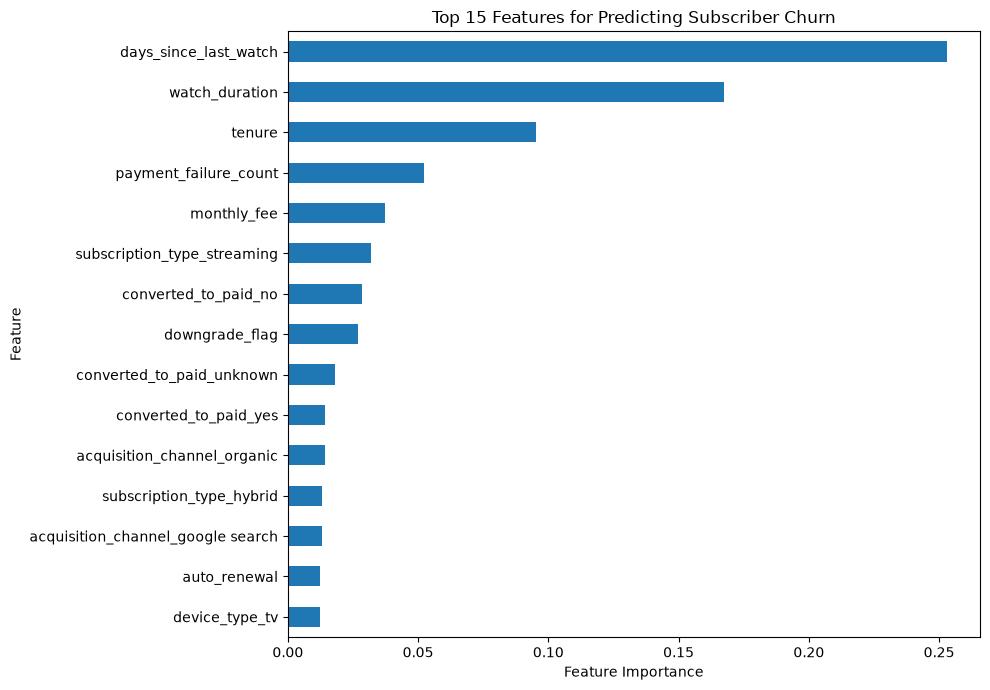

In [136]:
top_features = importance.head(15).sort_values(
    by='Importance',
    ascending=True
)

top_features.plot(
    x='Feature',
    y='Importance',
    kind='barh',
    legend=False,
    figsize=(10, 7)
)

plt.title('Top 15 Features for Predicting Subscriber Churn')
plt.xlabel('Feature Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

The model identifies days since last watch and watch duration as the most important predictors of subscriber churn, followed by tenure and payment failures.
This suggests that declining viewing engagement, subscription length, and payment difficulties are key factors for predicting churn, although feature importance does not establish causation.

In [137]:
# Check for possible target leakage
possible_leakage = [
    col for col in X.columns
    if any(term in col.lower() for term in [
        'retention_outcome',
        'churn_date',
        'cancellation_request_date'
    ])
]

print("Potential leakage columns:", possible_leakage)

Potential leakage columns: []


No data leakage was detected

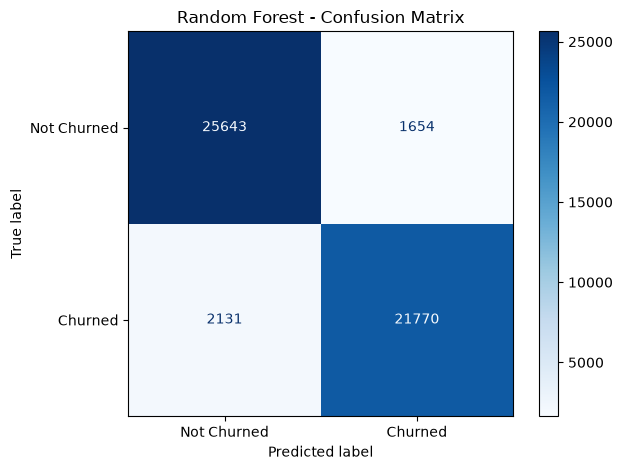

In [138]:
#Visualise the confusion matrix
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Generate predictions
y_pred = rf_model.predict(X_test)

# Plot confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=['Not Churned', 'Churned'],
    cmap='Blues',
    values_format='d'
)

plt.title('Random Forest - Confusion Matrix')
plt.tight_layout()
plt.show()

The Random Forest model correctly classified 25,643 non-churned customers and 21,770 churned customers, showing strong predictive performance for both classes. However, it incorrectly labeled 1,654 non-churned customers as churned and 2,131 churned customers as non-churned, meaning it misses some customers who are actually at risk of churn.

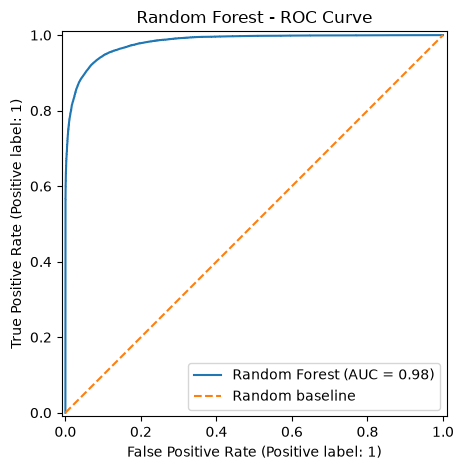

In [139]:
#Visualise the ROC curve

from sklearn.metrics import RocCurveDisplay
import matplotlib.pyplot as plt

# Get churn probabilities
y_prob = rf_model.predict_proba(X_test)[:, 1]

# Plot ROC curve
RocCurveDisplay.from_predictions(
    y_test,
    y_prob,
    name='Random Forest'
)

plt.plot([0, 1], [0, 1], linestyle='--',
         label='Random baseline')

plt.title('Random Forest - ROC Curve')
plt.legend()
plt.tight_layout()
plt.show()

The ROC curve shows that the Random Forest model has an AUC of 0.98, indicating excellent ability to distinguish between customers who will churn and those who will not. Because the curve stays close to the top-left corner and far above the random baseline, the model achieves a high true positive rate with a low false positive rate, making it highly effective for churn prediction.

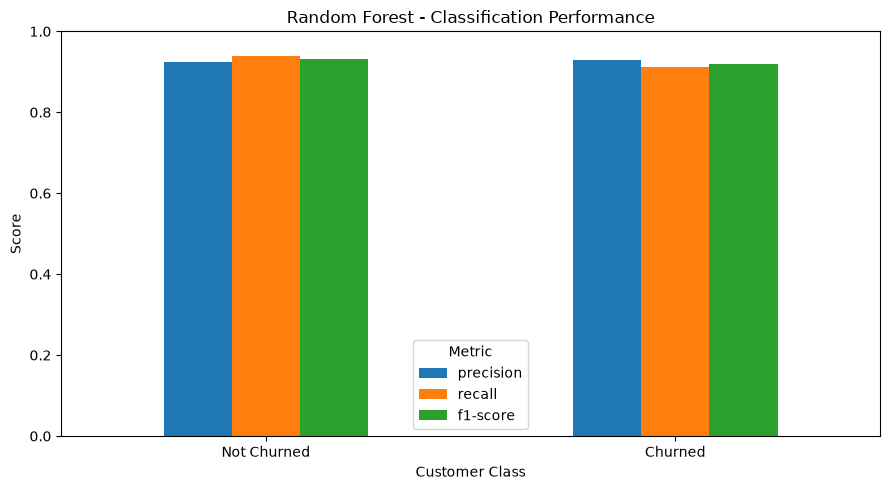

In [140]:
#Compare precision, recall and F1-score
# Generate classification report
report = classification_report(
    y_test,
    y_pred,
    target_names=['Not Churned', 'Churned'],
    output_dict=True
)

# Convert report to DataFrame
report_df = pandas.DataFrame(report).T

# Select the class-level metrics
metrics_df = report_df.loc[
    ['Not Churned', 'Churned'],
    ['precision', 'recall', 'f1-score']
]

# Plot metrics
metrics_df.plot(
    kind='bar',
    figsize=(9, 5),
    ylim=(0, 1),
    rot=0
)

plt.title('Random Forest - Classification Performance')
plt.xlabel('Customer Class')
plt.ylabel('Score')
plt.legend(title='Metric')
plt.tight_layout()
plt.show()

The Random Forest model shows strong and balanced performance across both classes, with precision, recall, and F1-scores all above 0.90, indicating highly accurate churn predictions. The model is slightly better at identifying non-churned customers (recall ≈ 0.94) than churned customers (recall ≈ 0.91), but overall maintains excellent classification performance for both groups.